# SBI: `P(N_HI, T | M_halo, b, V_max)` -- with the cut `b >= 0.1 R_200`

Trains the SBIBE network (Daniel Lopez-Cano) on the `FakeSpectra_DLAs` data.

**This is the variant with an impact-parameter cut.** Same as the notebook without the cut,
except that every sightline with `b < B_MIN_R200` (default 0.1) is dropped from training,
test and predictions. The measured covering fractions are not reliable below 0.1 R_200, so
the whole region leaves the problem instead of entering as bad data.

## What is being learned

`sbi` learns `q(theta | x)`. Here:

| SBIBE | Here |
|---|---|
| `theta` = cosmological parameters | `theta = (log10 N_HI, log10 T_fit)` -- what we infer |
| `xx` = `log10 P(k)`, 100 bins | `xx = (log10 M_200, log10 b/R_200, log10 V_max)` -- the conditioning |
| simulator = baccoemu | simulator = TNG50 + fake_spectra (already run, on disk) |

Note the inversion with respect to the classic use of SBI: the "observables" here are the
halo properties and the "parameters" are the absorber properties. Mathematically it is the
same thing -- conditional density estimation -- and `sbi` does not care. Physically, the
output is **an emulator of the scatter**: given a halo, the joint distribution of
`(N_HI, T)` of the sightlines that cross it.

## What the cut changes

* **`b = 0` is gone.** The three central sightlines per halo had the highest N_HI. Without
  them `log10(b)` is well defined over the whole sample, and the artificial floor the other
  notebook needed disappears.
* **The sample shrinks much more than the geometry suggests.** The cut removes ~27% of the
  sightlines, but the removed ones are the inner ones, precisely those most likely to pass
  the HCD cut -- expect to lose a much larger fraction of the HCDs than 27%.
* **The N_HI bimodality should shrink.** The high mode (~10^20.5) came from the central
  sightlines. The low mode, piled up just above the 10^17.2 cut, is still there. Compare the
  N_HI marginal with the one of the notebook without the cut: it is the most direct
  diagnostic of the effect.
* **The domain of the emulator changes.** The resulting network is only valid for
  `b >= B_MIN_R200`; do not extrapolate inwards.

## Pipeline

1. load one run, **apply the cut in `b`**, select `is_hcd`
2. Voigt fit -> `fit_T`, `fit_log_nhi`, `good`
3. build `theta` / `xx`, **split by `halo_id`**
4. train the MAF with `SNPE`/`NPE` (Daniel's code + version shim)
5. sample the posterior on the test set
6. truth vs SBI matrix

## 0. Environment

Run this cell first. It installs nothing -- it only says **which** env the kernel is using and what is missing in it.

In [1]:
# ==============================================================================
# CELL 0 -- Environment check (run this first)
# ==============================================================================
import sys, importlib.util
print("kernel :", sys.executable)      # <- check that this is the right env!
print("python :", sys.version.split()[0])

missing = [m for m in ("numpy", "pandas", "scipy", "matplotlib", "tqdm", "torch", "sbi")
         if importlib.util.find_spec(m) is None]

if missing:
    print("\nMISSING:", ", ".join(missing))
    print("\nInstall IN THE ENV OF THIS KERNEL. Inside the notebook, use the %pip magic")
    print("(`%pip` installs in the kernel env; `!pip` uses the pip on the PATH, which")
    print("can be another env -- the most common cause of 'installed but not found'):")
    print("\n    %pip install sbi")
    print("\nWithout a GPU, install the CPU torch first (avoids ~2.5 GB of CUDA):")
    print("\n    %pip install torch --index-url https://download.pytorch.org/whl/cpu")
    print("    %pip install sbi")
    print("\nAfter installing: RESTART THE KERNEL before going on.")
else:
    import torch, sbi
    print("\nok | torch", torch.__version__, "| sbi", sbi.__version__)

kernel : /home/vroberto/miniconda3/envs/skewerjax_fakespectra/bin/python
python : 3.11.14

ok | torch 2.13.0+cu130 | sbi 0.27.0


## 1. Configuracao

In [2]:
# ==============================================================================
# CELL 1 -- Config, imports and sbi compatibility shim
# ==============================================================================
import os, glob, pickle, warnings
import numpy as np
import pandas as pd
import scipy as sp
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.special import wofz
from scipy.optimize import curve_fit
from tqdm.auto import tqdm

import torch

# ---- shim: SBIBE uses the old sbi API, which no longer exists ---------------
# sbi < 0.23 : from sbi.inference import SNPE ; from sbi.utils.get_nn_models import posterior_nn
# sbi >= 0.23: SNPE -> NPE ; posterior_nn moved to sbi.neural_nets
# sbi >= 0.27: SNPE still exists but raises a DeprecationWarning (removed in 0.28)
try:
    from sbi.inference import NPE as _NPE            # sbi >= 0.23
except ImportError:
    from sbi.inference import SNPE as _NPE           # sbi <  0.23
try:
    from sbi.neural_nets import posterior_nn as _posterior_nn      # sbi >= 0.23
except ImportError:
    from sbi.utils.get_nn_models import posterior_nn as _posterior_nn
from sbi.utils import BoxUniform
import sbi
print("sbi", sbi.__version__, "| torch", torch.__version__)

plt.rc('font', family='serif', size=13)
plt.rcParams.update({"mathtext.fontset": "cm", "axes.linewidth": 1.4,
                     "xtick.direction": "in", "ytick.direction": "in",
                     "xtick.top": True, "ytick.right": True})

# ---- Voigt fit constants (same as in SBI_NHI_T.ipynb) ------------------------
K_B, M_P = 1.380649e-16, 1.67262192e-24
LAM_LYA, F_LYA, GAMMA = 1215.67e-8, 0.4164, 6.265e8
TAU_PRE = 0.0149736386
HUBBLE_H = 0.6774

T_LO, T_HI = 10, 5e6
BOUNDS = ([12.0, -500.0, T_LO], [23.0, 500.0, T_HI])
RMS_MAX = 0.1
SENS_MIN = 0.01

# ---- config of this notebook ------------------------------------------------
FILE_RUN = ("../data_TNG50-2_snap025_5runs/"
            "TNG50-2_z3_637Halos_HCDMode_Stratified_run0_seed42.pkl")
CACHE_FIT = "./cache_voigt_TNG50-2_run0_bmin.pkl"   # the fit is saved here

# Impact-parameter cut: drops EVERY sightline with
# b < B_MIN_R200 (in units of R_200), including the three central b = 0 ones.
# Reason: the measured covering fractions are not reliable below
# 0.1 R_200 -- there the resolution of the simulation and the HCD definition
# itself dominate over the physics. The cut is applied BEFORE the Voigt fit,
# so it also makes the most expensive step of the notebook cheaper.
B_MIN_R200 = 0.1

# Where the N_HI in theta comes from:
#   'sim' -> df['log_n_hi'], the integrated column of the simulation (the truth)
#   'fit' -> df['fit_log_nhi'], what the Voigt profile recovers
# 'sim' is the default: it is the "true" N_HI, and keeps theta[0] independent
# of the fit pathologies. Switching to 'fit' makes (N_HI, T) consistent with each other,
# both coming from the same fit.
NHI_SOURCE = 'sim'

TEST_FRACTION = 0.2      # fraction of HALOS (not sightlines) kept for the test
N_POST_SAMPLES = 1000    # posterior samples per test object
SEED = 0

rng = np.random.default_rng(SEED)

sbi 0.27.0 | torch 2.13.0+cu130


## 2. Load the run and cut in `b`

A single file. `df.attrs` carries the shared grids.

The cut in `b` comes **before** `is_hcd` and before the Voigt fit: besides being the
definition of the problem, it avoids fitting profiles that would be discarded later.

`is_hcd` selects the sightlines that really have absorption (the others have `flux = 1` by
construction -- a result of the 10^17.2 selection, not missing data).

In [3]:
# ==============================================================================
# CELL 2 -- Load the run and select the HCDs
# ==============================================================================
df = pd.read_pickle(FILE_RUN)
meta = dict(df.attrs)
v_grid = np.asarray(meta['v_grid'], dtype=float)

df['halo_mass_msun'] = df['halo_mass'] * 1e10 / HUBBLE_H

# --- impact-parameter cut, BEFORE anything else -----------------------------
# b = 0 goes too: 0 < B_MIN_R200. Since b only appears through log10 later, this
# has the useful side effect of removing log10(0) from the problem.
n_before = len(df)
b_all_raw = np.sort(df['r_multiplier'].unique())
df = df[df['r_multiplier'] >= B_MIN_R200].copy()
b_kept = np.sort(df['r_multiplier'].unique())
print(f"cut b >= {B_MIN_R200} R_200:")
print(f"  b grid     : {len(b_all_raw)} values -> {len(b_kept)} "
      f"(smallest kept: {b_kept.min():.4g})")
print(f"  sightlines : {n_before:,} -> {len(df):,} "
      f"({100*len(df)/n_before:.1f}% kept)")
print(f"  dropped    : b = 0 (central) and {len(b_all_raw)-len(b_kept)-1} "
      f"log-spaced values\n")

hcd = df[df['is_hcd']].copy()
print(f"{len(df):,} sightlines -> {len(hcd):,} HCDs "
      f"({100*len(hcd)/len(df):.2f}%)   nbins={meta['nbins']}, "
      f"dv={meta['dvbin']:.1f} km/s, z={meta['redshift']:.3f}")
print(f"halos: {df['halo_id'].nunique()} total, {hcd['halo_id'].nunique()} with >=1 HCD")

# how much of the parameter space is left after the HCD cut
for c, lab in [('halo_mass_msun', 'M_200 [Msun]'),
               ('r_multiplier', 'b [R_200]'),
               ('halo_vmax', 'V_max [km/s]')]:
    s = hcd[c].dropna()
    print(f"  {lab:<16} [{s.min():.4g}, {s.max():.4g}]  "
          f"NaN: {hcd[c].isna().sum():,}")

corte b >= 0.1 R_200:
  grade de b : 31 valores -> 22 (menor mantido: 0.1048)
  linhas     : 231,231 -> 168,168 (72.7% mantidas)
  descartados: b = 0 (centrais) e 8 valores log-spaced

168,168 linhas de visada -> 51,589 HCDs (30.68%)   nbins=396, dv=10.0 km/s, z=3.008
halos: 637 total, 637 com >=1 HCD
  M_200 [Msun]     [1.006e+10, 8.888e+12]  NaN: 0
  b [R_200]        [0.1048, 50]  NaN: 0
  V_max [km/s]     [41.45, 1173]  NaN: 0


## 3. Voigt fit

Same code as the notebook without the cut (`voigt_flux`, `fit_one`, `is_good`,
`hi_weighted_T`). The only addition is the disk cache: the fit takes a few minutes and does
not change, so there is no reason to redo it at every re-run.

In [4]:
# ==============================================================================
# CELL 3 -- Voigt profile parametrised by T, and the fit (cached)
# ==============================================================================
def voigt_flux(v_kms, log_nhi, v0_kms, T_K):
    """Transmitted Lya flux of one component: F = exp(-tau)."""
    b = np.sqrt(2.0 * K_B * T_K / M_P)                  # cm/s
    u = (np.asarray(v_kms, dtype=float) - v0_kms) * 1e5 / b
    a = GAMMA * LAM_LYA / (4.0 * np.pi * b)
    H = np.real(wofz(u + 1j * a))
    return np.exp(-(TAU_PRE * F_LYA * LAM_LYA * 10.0**log_nhi / b) * H)


def hi_weighted_T(temp, n_hi_col):
    """N_HI-weighted temperature of the sightline (the truth of the simulation)."""
    w = np.asarray(n_hi_col, dtype=float)
    if w.sum() <= 0:
        return np.nan
    return float(np.sum(w * np.asarray(temp, dtype=float)) / w.sum())


def T_sensitivity(log_nhi, v0, T, v=None):
    """How much the spectrum changes when T is scaled by 1/3 and 3."""
    v = v_grid if v is None else v
    return float(np.sqrt(np.mean(
        (voigt_flux(v, log_nhi, v0, 3 * T) - voigt_flux(v, log_nhi, v0, T / 3))**2)))


def fit_one(flux, log_nhi_guess, v0_guess, v=None):
    """Fit one sightline. Returns (log_nhi, v0, T, rms, sens) or NaNs."""
    v = v_grid if v is None else v
    flux = np.asarray(flux, dtype=float)
    if not np.isfinite(flux).all() or flux.min() > 0.99:
        return (np.nan,) * 5
    p0 = [np.clip(log_nhi_guess, 12.5, 22.5), np.clip(v0_guess, -400, 400), 3e4]
    try:
        popt, _ = curve_fit(voigt_flux, v, flux, p0=p0, bounds=BOUNDS, maxfev=20000)
    except (RuntimeError, ValueError):
        return (np.nan,) * 5
    rms = float(np.sqrt(np.mean((flux - voigt_flux(v, *popt))**2)))
    return popt[0], popt[1], popt[2], rms, T_sensitivity(*popt, v=v)


def is_good(T, rms, sens):
    """True when T is a real measurement, not an artefact of a flat direction."""
    return bool(np.isfinite(T) and rms < RMS_MAX
                and T_LO * 1.01 < T < T_HI * 0.99
                and sens > SENS_MIN)


def fit_frame(h, vg, desc):
    r = [fit_one(f, lN, v0, v=vg) for f, lN, v0 in
         tqdm(zip(h['flux'], h['log_n_hi'], h['vel_peak_shift']),
              total=len(h), desc=desc)]
    h[['fit_log_nhi', 'fit_v0', 'fit_T', 'fit_rms', 'fit_sens']] = np.array(r, float)
    h['T_sim'] = [hi_weighted_T(t, n) for t, n in zip(h['temp'], h['n_hi_col'])]
    h['good'] = [is_good(T, rm, s) for T, rm, s in
                 zip(h['fit_T'], h['fit_rms'], h['fit_sens'])]
    return h


FIT_COLS = ['fit_log_nhi', 'fit_v0', 'fit_T', 'fit_rms', 'fit_sens', 'T_sim', 'good']

if os.path.exists(CACHE_FIT):
    cached = pd.read_pickle(CACHE_FIT)
    if len(cached) == len(hcd) and (cached.index == hcd.index).all():
        hcd[FIT_COLS] = cached[FIT_COLS]
        print(f"fit loaded from the cache: {CACHE_FIT}")
    else:
        print("cache does not match this run, redoing the fit")
        hcd = fit_frame(hcd, v_grid, "Voigt")
        hcd[FIT_COLS].to_pickle(CACHE_FIT)
else:
    hcd = fit_frame(hcd, v_grid, "Voigt")
    hcd[FIT_COLS].to_pickle(CACHE_FIT)
    print(f"fit saved to {CACHE_FIT}")

good = hcd['good'].to_numpy(bool)
print(f"\n{good.sum():,}/{len(hcd):,} fits with T constrained "
      f"({100*good.sum()/len(hcd):.1f}%)")
print(f"  median (fit - true) log N_HI = "
      f"{(hcd['fit_log_nhi'] - hcd['log_n_hi']).median():+.3f} dex")
print(f"  median T_fit / T_sim          = "
      f"{(hcd.loc[good, 'fit_T'] / hcd.loc[good, 'T_sim']).median():.2f}")

# WARNING: the `good` cut is NOT random -- it preferentially removes
# the high-N_HI systems, where the damping wings dominate and T stops
# being identifiable. How much, per class:
for lab, m in [("LLS     17.2-19.0", hcd['log_n_hi'].between(17.2, 19.0)),
               ("sub-DLA 19.0-20.3", hcd['log_n_hi'].between(19.0, 20.3)),
               ("DLA       > 20.3 ", hcd['log_n_hi'] > 20.3)]:
    if m.sum():
        print(f"  {lab}  n={m.sum():6,}  T constrained: "
              f"{100*(good & m.to_numpy()).sum()/m.sum():5.1f}%")

Voigt:   0%|          | 0/51589 [00:00<?, ?it/s]

fit salvo em ./cache_voigt_TNG50-2_run0_bmin.pkl

37,359/51,589 fits com T constrangido (72.4%)
  mediana (fit - true) log N_HI = -0.042 dex
  mediana T_fit / T_sim         = 4.31
  LLS     17.2-19.0  n=22,739  T constrangido:  97.8%
  sub-DLA 19.0-20.3  n=18,784  T constrangido:  74.1%
  DLA       > 20.3   n=10,066  T constrangido:  12.0%


## 4. Build `theta` and `xx`

**`theta` (what the network infers), 2D**

| | |
|---|---|
| `log10 N_HI` | `log_n_hi` (or `fit_log_nhi`, see `NHI_SOURCE`) |
| `log10 T_fit` | `fit_T`, from the Voigt fit |

**`xx` (the conditioning), 3D**

| | |
|---|---|
| `log10 M_200` | `halo_mass * 1e10 / h` |
| `log10 b/R_200` | `r_multiplier`, now always >= `B_MIN_R200` |
| `log10 V_max` | `halo_vmax`, of the central subhalo |

All in log because the three quantities span decades and the pipeline sampling is already
log-uniform in `b`.

**Split by halo, not by sightline.** The sightlines are not independent: there are several
skewers per halo. A random split of sightlines puts the same halo in training and
validation, the network memorises the halo through the pair `(M_200, V_max)`, and
`best_validation_log_prob` becomes optimistic. The `assert` at the end of the cell makes
sure there is no leakage.

In [5]:
# ==============================================================================
# CELL 4 -- theta / xx, quality cuts and split by halo
# ==============================================================================
# --- log10 of b, no floor ----------------------------------------------------
# With the cut b >= B_MIN_R200 there is no b = 0 left, so log10 is direct: the
# artificial floor the notebook without the cut needed is gone.
b_all = np.sort(hcd['r_multiplier'].unique())
assert b_all.min() >= B_MIN_R200, "b below the cut left -- check CELL 2"
dex_step = np.median(np.diff(np.log10(b_all)))
print(f"b grid: {len(b_all)} values from {b_all.min():.4g} to {b_all.max():.4g} "
      f"R_200, step {dex_step:.4f} dex")


def log_b(b):
    return np.log10(np.asarray(b, dtype=float))


# --- quality mask ------------------------------------------------------------
nhi_col = 'log_n_hi' if NHI_SOURCE == 'sim' else 'fit_log_nhi'
mask = (hcd['good'].to_numpy(bool)
        & np.isfinite(hcd['halo_vmax'].to_numpy(float))     # no central subhalo -> NaN
        & (hcd['halo_vmax'].to_numpy(float) > 0)
        & np.isfinite(hcd[nhi_col].to_numpy(float))
        & (hcd[nhi_col].to_numpy(float) > 0)
        & np.isfinite(hcd['fit_T'].to_numpy(float)))
sel = hcd[mask]
print(f"\nafter the cuts: {len(sel):,} sightlines, "
      f"{sel['halo_id'].nunique()} halos")

theta = np.column_stack([sel[nhi_col].to_numpy(float),
                         np.log10(sel['fit_T'].to_numpy(float))])
xx = np.column_stack([np.log10(sel['halo_mass_msun'].to_numpy(float)),
                      log_b(sel['r_multiplier'].to_numpy(float)),
                      np.log10(sel['halo_vmax'].to_numpy(float))])
halo_ids = sel['halo_id'].to_numpy()

THETA_KEYS = ['log_nhi', 'log_T']
XX_KEYS = ['log_M200', 'log_b', 'log_vmax']
THETA_TITLES = [r'$\log_{10} N_{\rm HI}$', r'$\log_{10} T_{\rm fit}$']

print(f"theta {theta.shape}  xx {xx.shape}")
for i, k in enumerate(THETA_KEYS):
    print(f"  theta[{k}]  [{theta[:, i].min():7.3f}, {theta[:, i].max():7.3f}]")
for i, k in enumerate(XX_KEYS):
    print(f"  xx   [{k}]  [{xx[:, i].min():7.3f}, {xx[:, i].max():7.3f}]")

# --- split BY HALO -----------------------------------------------------------
uh = np.unique(halo_ids)
uh_shuffled = rng.permutation(uh)
n_test = max(1, int(TEST_FRACTION * len(uh)))
halos_test = set(uh_shuffled[:n_test].tolist())
is_test = np.array([h in halos_test for h in halo_ids])
is_train = ~is_test

theta_train, xx_train = theta[is_train], xx[is_train]
theta_test, xx_test = theta[is_test], xx[is_test]
print(f"\ntrain: {is_train.sum():,} sightlines / {len(uh) - n_test} halos")
print(f"test : {is_test.sum():,} sightlines / {n_test} halos")
assert not (set(halo_ids[is_train]) & set(halo_ids[is_test])), "halo leakage!"

# --- prior bounds ------------------------------------------------------------
# BoxUniform over theta, with a 5% margin so the posterior does not touch the edge.
PAD = 0.05
dict_bounds = {}
for i, k in enumerate(THETA_KEYS):
    lo, hi = theta_train[:, i].min(), theta_train[:, i].max()
    d = PAD * (hi - lo)
    dict_bounds[k] = [float(lo - d), float(hi + d)]
print("\ndict_bounds:", {k: [round(a, 3), round(b, 3)] for k, (a, b) in dict_bounds.items()})

grade de b: 22 valores de 0.1048 a 50 R_200, passo 0.1276 dex

apos os cortes: 37,359 linhas de visada, 637 halos
theta (37359, 2)  xx (37359, 3)
  theta[log_nhi]  [ 17.200,  21.037]
  theta[log_T]  [  4.046,   6.516]
  xx   [log_M200]  [ 10.003,  12.949]
  xx   [log_b]  [ -0.980,   1.699]
  xx   [log_vmax]  [  1.617,   3.069]

treino: 29,886 linhas / 510 halos
teste : 7,473 linhas / 127 halos

dict_bounds: {'log_nhi': [17.008, 21.229], 'log_T': [3.922, 6.64]}


## 5. SBIBE

Daniel's code (`SBIBE/sbi_utils.py`), vendored here instead of imported because
`import SBIBE` pulls `sbi_data_utils`, which does `import baccoemu`. The changes with respect
to the original are marked with `# CHANGE:`.

`get_prior` and `train_model` are his. `compute_ranks` was fixed -- see the note at the end
of the notebook.

In [6]:
# ==============================================================================
# CELL 5 -- vendored SBIBE (Daniel's sbi_utils.py)
# ==============================================================================
def get_prior(dict_bounds):
    """Same as SBIBE. The ORDER of the dict is the order of the parameters everywhere."""
    lower_bound = np.vstack(tuple(dict_bounds[key] for key in dict_bounds))[:, 0]
    upper_bound = np.vstack(tuple(dict_bounds[key] for key in dict_bounds))[:, 1]
    lower_bound, upper_bound = (torch.from_numpy(lower_bound.astype('float32')),
                                torch.from_numpy(upper_bound.astype('float32')))
    return BoxUniform(lower_bound, upper_bound)


def train_model(theta_train, xx_train, prior,
                num_hidden_features=64, num_transforms=8, num_blocks=4,
                training_batch_size=16, learning_rate=0.00031,
                validation_fraction=0.2,
                seed=0, max_num_epochs=2**31 - 1, stop_after_epochs=20):
    """SNPE/NPE with a MAF. Same structure as SBIBE.

    CHANGE 1: `seed` is an argument (the original had torch.manual_seed(0)
               hardcoded, so every run used the same seed and the training
               variance could not be estimated).
    CHANGE 2: `max_num_epochs` / `stop_after_epochs` exposed.
    CHANGE 3: _posterior_nn / _NPE come from the shim in CELL 1.

    NO StandardScaler needed: posterior_nn already z-scores internally
    (z_score_theta='independent', z_score_x='independent' by default). That is
    why the scaler is commented out in Daniel's original notebook.
    """
    torch.manual_seed(seed)

    density_estimator_build_fun = _posterior_nn(
        model='maf',
        hidden_features=num_hidden_features,
        num_transforms=num_transforms,
        num_blocks=num_blocks,
    )

    inference = _NPE(prior=prior, density_estimator=density_estimator_build_fun)

    inference.append_simulations(
        torch.from_numpy(theta_train.astype('float32')),
        torch.from_numpy(xx_train.astype('float32')),
    )

    density_estimator = inference.train(
        training_batch_size=training_batch_size,
        validation_fraction=validation_fraction,
        learning_rate=learning_rate,
        max_num_epochs=max_num_epochs,
        stop_after_epochs=stop_after_epochs,
        show_train_summary=True,
    )

    posterior = inference.build_posterior(density_estimator)
    return inference, posterior


def sample_posteriors_theta_test(posterior, xx_test, dict_bounds,
                                 N_samples=1000, batch_size=512):
    """Sample the posterior for each test x. Returns (N_test, N_samples, D).

    CHANGE: the original is a Python loop calling posterior.sample() once
    per object (~1000 objects there; tens of thousands here). Uses
    sample_batched when available, falling back to the original loop.
    """
    D = len(dict_bounds)
    N = xx_test.shape[0]
    out = np.zeros((N, N_samples, D), dtype=np.float32)
    xt = torch.from_numpy(xx_test.astype('float32'))

    if hasattr(posterior, "sample_batched"):
        for s in tqdm(range(0, N, batch_size), desc="posterior"):
            e = min(s + batch_size, N)
            smp = posterior.sample_batched((N_samples,), x=xt[s:e],
                                           show_progress_bars=False)
            out[s:e] = smp.permute(1, 0, 2).cpu().numpy()   # (S,B,D)->(B,S,D)
    else:
        for ii in tqdm(range(N), desc="posterior"):
            out[ii] = posterior.sample((N_samples,), x=xt[ii],
                                       show_progress_bars=False).cpu().numpy()
    return out


def compute_ranks(theta, inferred_theta):
    """SBC rank: how many posterior samples lie below the truth.

    CHANGE: the original does np.argsort(tmp, axis=1)[:, 0, :], which returns the
    INDEX OF THE SMALLEST element, not the rank of the truth. Under perfect
    calibration both histograms are flat, so the bug is easy to miss -- but the
    original is blind to posteriors that are too wide, which is exactly the regime
    one ends up in when marginalising over nuisance parameters.
    """
    return (np.asarray(inferred_theta) < np.asarray(theta)[:, None, :]).sum(axis=1)

## 6. Training

Hyperparameters: Daniel's defaults, with one exception. His `training_batch_size=16` makes
sense for 3000 points; here there are tens of thousands of sightlines, and batch 16 means
thousands of steps per epoch. Raised to 512.

`stop_after_epochs=20` is the early stopping of `sbi`: it stops when the validation does not
improve for 20 epochs.

In [7]:
# ==============================================================================
# CELL 6 -- Training
# ==============================================================================
prior = get_prior(dict_bounds)

inference, posterior = train_model(
    theta_train, xx_train, prior,
    num_hidden_features=64,
    num_transforms=8,
    num_blocks=4,
    training_batch_size=512,     # CHANGE: 16 in the original (meant for N=3000)
    learning_rate=0.00031,
    validation_fraction=0.2,
    seed=SEED,
    stop_after_epochs=20,
)

# `inference.summary` changed key between sbi versions:
#   sbi < 0.23 : 'best_validation_log_prob'  (log-prob, HIGHER is better)
#   sbi >= 0.23: 'best_validation_loss'      (loss,     LOWER is better)
# The sweep in Daniel's sbi_wandb_utils.py uses the old key: besides a
# KeyError with the new sbi, if one only renames the key the sweep optimises
# in the wrong direction, because the sign flipped.
def best_validation(inference):
    s = inference.summary
    if 'best_validation_log_prob' in s:
        return float(s['best_validation_log_prob'][0]), 'log_prob (higher = better)'
    return float(s['best_validation_loss'][0]), 'loss (lower = better)'


val, kind = best_validation(inference)
print(f"\nbest validation: {val:.4f}   [{kind}]")
print(f"epochs trained  : {inference.summary['epochs_trained'][0]}")

 Neural network successfully converged after 75 epochs.
        -------------------------
        ||||| ROUND 1 STATS |||||:
        -------------------------
        Epochs trained: 75
        Best validation performance: 0.9908
        -------------------------
        

melhor validacao: 0.9908   [loss (menor = melhor)]
epocas treinadas : 75


## 7. Sample the posterior on the test set

For each test sightline, `N_POST_SAMPLES` samples of `q(log N_HI, log T | M, b, V_max)`.

In [8]:
# ==============================================================================
# CELL 7 -- Posterior on the test set
# ==============================================================================
inferred_theta_test = sample_posteriors_theta_test(
    posterior, xx_test, dict_bounds, N_samples=N_POST_SAMPLES)
print("inferred_theta_test:", inferred_theta_test.shape)

# --- quick numerical diagnostic ----------------------------------------------
med = np.median(inferred_theta_test, axis=1)
print(f"\n{'':12s} {'bias':>8s} {'rms':>8s} {'sigma_post':>11s} {'cov.68%':>9s}")
for i, k in enumerate(THETA_KEYS):
    truth = theta_test[:, i]
    lo = np.percentile(inferred_theta_test[:, :, i], 16, axis=1)
    hi = np.percentile(inferred_theta_test[:, :, i], 84, axis=1)
    cov = np.mean((truth >= lo) & (truth <= hi))
    print(f"{k:12s} {np.mean(med[:, i] - truth):+8.3f} "
          f"{np.std(med[:, i] - truth):8.3f} "
          f"{np.std(inferred_theta_test[:, :, i], axis=1).mean():11.3f} "
          f"{100*cov:8.1f}%")
# coverage ~68% = calibrated posterior. Much lower = overconfident;
# much higher = too wide.

posterior:   0%|          | 0/15 [00:00<?, ?it/s]

/tmp/ipykernel_25527/1366776567.py:75: UserWarning: Capping max_sampling_batch_size from 10000 to 195 to avoid excessive memory usage.
  smp = posterior.sample_batched((N_samples,), x=xt[s:e],
/tmp/ipykernel_25527/1366776567.py:75: UserWarning: Capping max_sampling_batch_size from 10000 to 327 to avoid excessive memory usage.
  smp = posterior.sample_batched((N_samples,), x=xt[s:e],


inferred_theta_test: (7473, 1000, 2)

                 bias      rms  sigma_post   cob.68%
log_nhi        +0.019    0.807       0.791     66.6%
log_T          -0.024    0.251       0.256     70.2%


## 8. Truth vs SBI

Columns are the TNG values, rows are the SBI ones, so each 2D panel is a joint density over
the whole test set.

* **lower left** `N_HI(SBI)` vs `N_HI(TNG)` -- recovery test, with the 1:1 line
* **centre** `T(SBI)` vs `T(TNG)` -- recovery test, with the 1:1 line
* **upper left** and **lower centre** -- cross terms: how much the network relies on the
  N_HI-T correlation it learned

**Naming.** `fit_T` in the pipeline is the Voigt temperature measured on the TNG spectrum --
it **is** `theta[1]`, the truth the network tries to infer. So "fit" cannot also mean "SBI
output"; the axes are labelled `(TNG)` and `(SBI)`. It is `fit_T`, not `T_sim` (the
N_HI-weighted temperature of the simulation).

**Careful with `r` and `sigma`.** If the conditional is multimodal, a single posterior draw
can fall in any mode, which inflates `sigma` and lowers `r` even with a perfect model. In
that case judge by the overlap of the marginals and use the per-mode statistics printed at
the end.

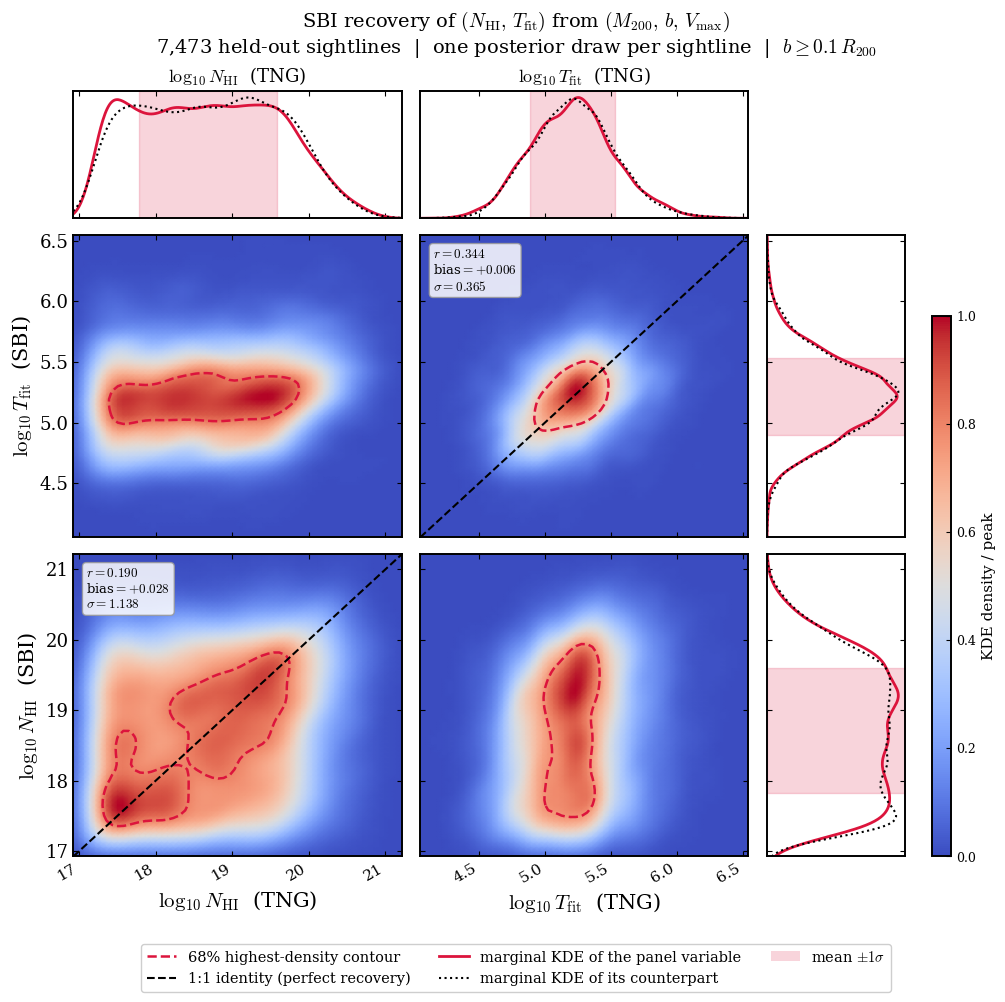

GLOBAL
  log N_HI                 n= 7,473  mean  18.685 ->  18.714  std  0.899 ->  0.889  r= 0.190  bias=+0.028  sigma=1.138  KS D=0.0218
  log T_fit                n= 7,473  mean   5.210 ->   5.217  std  0.321 ->  0.316  r= 0.344  bias=+0.006  sigma=0.365  KS D=0.0183

low  (N_HI < 19.0)
  log N_HI                 n= 4,557  mean  18.082 ->  18.598  std  0.530 ->  0.871  r= 0.070  bias=+0.516  sigma=0.987  KS D=0.3526
  log T_fit                n= 4,557  mean   5.129 ->   5.186  std  0.298 ->  0.316  r= 0.289  bias=+0.057  sigma=0.366  KS D=0.0766

high (N_HI > 19.0)
  log N_HI                 n= 2,916  mean  19.628 ->  18.895  std  0.417 ->  0.888  r= 0.157  bias=-0.733  sigma=0.920  KS D=0.5082
  log T_fit                n= 2,916  mean   5.338 ->   5.265  std  0.314 ->  0.311  r= 0.377  bias=-0.073  sigma=0.349  KS D=0.0926


In [9]:
# ==============================================================================
# CELL 8 -- Truth vs inferred: full 2x2 matrix with edge marginals
#
#     bottom-left  N_HI(SBI) vs N_HI(TNG)   recovery test, with the 1:1 line
#     middle       T(SBI)    vs T(TNG)      recovery test, with the 1:1 line
#     top-left     T(SBI)    vs N_HI(TNG)   cross term
#     bottom-mid   N_HI(SBI) vs T(TNG)      cross term
#
# ELEMENTS
#   coolwarm map   KDE density of the pair, each panel scaled to its own peak
#   crimson dashed smallest region containing PROB of the density
#   black dashed   1:1 identity
#   crimson solid  marginal KDE of that panel's variable
#   black dotted   marginal KDE of its counterpart (TNG vs SBI of the same
#                  quantity) -- overlap means the population was reproduced
#   pink band      mean +/- 1 sigma of the crimson marginal
#
# STATS BOX
#   r      Pearson correlation between TNG and SBI
#   bias   mean offset in dex, should sit near zero
#   sigma  scatter about the 1:1 line = the irreducible uncertainty, i.e. how
#          much (M200, b, Vmax) genuinely fails to determine the quantity
# ==============================================================================
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

CMAP, C_CONT, C_ID, C_CPT = 'coolwarm', 'crimson', 'k', 'k'
PROB = 0.68


def _kde2(x, y, xl, yl, n=60, mx=20000):
    """KDE of (x, y) on a grid. Subsampled: KDE is O(n_data * n_eval)."""
    if len(x) > mx:
        k = np.random.default_rng(0).choice(len(x), mx, replace=False)
        x, y = x[k], y[k]
    xi, yi = np.mgrid[xl[0]:xl[1]:n * 1j, yl[0]:yl[1]:n * 1j]
    zi = sp.stats.gaussian_kde(np.vstack([x, y]))(
        np.vstack([xi.ravel(), yi.ravel()])).reshape(xi.shape)
    return xi, yi, zi


def _level(zi, prob):
    """Density threshold of the smallest region holding `prob` of the mass."""
    z = zi / zi.sum()
    t = np.linspace(0, z.max(), 1000)
    I = ((z >= t[:, None, None]) * z).sum(axis=(1, 2))
    return float(sp.interpolate.interp1d(I, t)(1 - prob)) * zi.sum()


def _sty(ax):
    [s.set_linewidth(1.4) for s in ax.spines.values()]
    ax.tick_params(which='both', direction='in', top=True, right=True)


def _panel(ax, x, y, xl, yl, identity=False):
    xi, yi, zi = _kde2(x, y, xl, yl)
    pc = ax.pcolormesh(xi, yi, zi / zi.max(), shading='gouraud',
                       cmap=CMAP, vmin=0, vmax=1)
    ax.contour(xi, yi, zi, levels=[_level(zi, PROB)], colors=[C_CONT],
               linewidths=1.8, linestyles='--')
    if identity:
        lo, hi = max(xl[0], yl[0]), min(xl[1], yl[1])
        ax.plot([lo, hi], [lo, hi], color=C_ID, lw=1.5, ls='--')
        ax.text(0.04, 0.96,
                f"$r={np.corrcoef(x, y)[0, 1]:.3f}$\n"
                f"bias$={np.mean(y - x):+.3f}$\n$\\sigma={np.std(y - x):.3f}$",
                transform=ax.transAxes, va='top', ha='left', fontsize=9.5,
                bbox=dict(fc='white', ec='0.6', alpha=0.85,
                          boxstyle='round,pad=0.3'))
    ax.set_xlim(*xl)
    ax.set_ylim(*yl)
    return pc


def _marg(ax, v, counterpart, xl, rot=False):
    g = np.linspace(*xl, 300)
    d = sp.stats.gaussian_kde(v)(g)
    dc = sp.stats.gaussian_kde(counterpart)(g)
    m, s = v.mean(), v.std()
    if rot:                                    # row marginal: density on x
        ax.plot(d, g, color=C_CONT, lw=2.0)
        ax.plot(dc, g, color=C_CPT, lw=1.5, ls=':')
        ax.axhspan(m - s, m + s, color=C_CONT, alpha=0.18)
        ax.set_ylim(*xl); ax.set_xlim(0, None)
        ax.set_yticklabels([]); ax.set_xticks([])
    else:                                      # column marginal: density on y
        ax.plot(g, d, color=C_CONT, lw=2.0)
        ax.plot(g, dc, color=C_CPT, lw=1.5, ls=':')
        ax.axvspan(m - s, m + s, color=C_CONT, alpha=0.18)
        ax.set_xlim(*xl); ax.set_ylim(0, None)
        ax.set_xticklabels([]); ax.set_yticks([])


# ---- one SBI value per test object ------------------------------------------
# A single posterior draw, not the median: the median averages over the
# posterior width and would shrink the inferred scatter, so the two populations
# would stop being comparable.
USE_MEDIAN = False

if USE_MEDIAN:
    theta_pred = np.median(inferred_theta_test, axis=1)
    draw_note = 'posterior median per sightline'
else:
    _i = rng.integers(0, inferred_theta_test.shape[1],
                      inferred_theta_test.shape[0])
    theta_pred = inferred_theta_test[np.arange(len(_i)), _i]
    draw_note = 'one posterior draw per sightline'

n_tng, t_tng = theta_test[:, 0], theta_test[:, 1]
n_sbi, t_sbi = theta_pred[:, 0], theta_pred[:, 1]

PAD = 0.02


def _lim(*arrs):
    v = np.concatenate(arrs)
    lo, hi = v.min(), v.max()
    p = PAD * (hi - lo)
    return (lo - p, hi + p)


Ln, Lt = _lim(n_tng, n_sbi), _lim(t_tng, t_sbi)

TN_R = r'$\log_{10} N_{\rm HI}$  (TNG)'
TT_R = r'$\log_{10} T_{\rm fit}$  (TNG)'
TN_S = r'$\log_{10} N_{\rm HI}$  (SBI)'
TT_S = r'$\log_{10} T_{\rm fit}$  (SBI)'

fig = plt.figure(figsize=(10.8, 10.2))
gs = fig.add_gridspec(3, 3, width_ratios=[1, 1, 0.42],
                      height_ratios=[0.42, 1, 1], hspace=0.07, wspace=0.07,
                      left=0.09, right=0.86, top=0.895, bottom=0.145)

# ---- top marginals: the TNG quantities --------------------------------------
a00 = fig.add_subplot(gs[0, 0]); _sty(a00)
_marg(a00, n_tng, n_sbi, Ln)
a00.set_title(TN_R, fontsize=13, pad=6)

a01 = fig.add_subplot(gs[0, 1]); _sty(a01)
_marg(a01, t_tng, t_sbi, Lt)
a01.set_title(TT_R, fontsize=13, pad=6)

# ---- row 1: T (SBI) ---------------------------------------------------------
a10 = fig.add_subplot(gs[1, 0]); _sty(a10)
pc = _panel(a10, n_tng, t_sbi, Ln, Lt)
a10.set_ylabel(TT_S, fontsize=15); a10.set_xticklabels([])

a11 = fig.add_subplot(gs[1, 1]); _sty(a11)
_panel(a11, t_tng, t_sbi, Lt, Lt, identity=True)       # T recovery test
a11.set_xticklabels([]); a11.set_yticklabels([])

a12 = fig.add_subplot(gs[1, 2]); _sty(a12)
_marg(a12, t_sbi, t_tng, Lt, rot=True)

# ---- row 2: N_HI (SBI) ------------------------------------------------------
a20 = fig.add_subplot(gs[2, 0]); _sty(a20)
_panel(a20, n_tng, n_sbi, Ln, Ln, identity=True)       # N_HI recovery test
a20.set_ylabel(TN_S, fontsize=15); a20.set_xlabel(TN_R, fontsize=15)

a21 = fig.add_subplot(gs[2, 1]); _sty(a21)
_panel(a21, t_tng, n_sbi, Lt, Ln)
a21.set_xlabel(TT_R, fontsize=15); a21.set_yticklabels([])

a22 = fig.add_subplot(gs[2, 2]); _sty(a22)
_marg(a22, n_sbi, n_tng, Ln, rot=True)

for ax in (a20, a21):
    for t in ax.get_xticklabels():
        t.set_rotation(30); t.set_ha('right'); t.set_fontsize(11)

# ---- legend below, colourbar on the right -----------------------------------
fig.legend(
    [Line2D([0], [0], color=C_CONT, lw=1.8, ls='--'),
     Line2D([0], [0], color=C_ID, lw=1.5, ls='--'),
     Line2D([0], [0], color=C_CONT, lw=2.0),
     Line2D([0], [0], color=C_CPT, lw=1.5, ls=':'),
     Patch(fc=C_CONT, alpha=0.18, ec='none')],
    [f'{int(PROB*100)}% highest-density contour',
     '1:1 identity (perfect recovery)',
     'marginal KDE of the panel variable',
     'marginal KDE of its counterpart',
     r'mean $\pm 1\sigma$'],
    loc='lower center', bbox_to_anchor=(0.5, 0.005), ncol=3,
    fontsize=10.5, frameon=True, framealpha=0.95)

cax = fig.add_axes([0.885, 0.145, 0.018, 0.53])
cb = fig.colorbar(pc, cax=cax)
cb.set_label('KDE density / peak', fontsize=11)
cb.ax.tick_params(labelsize=9)

fig.suptitle(
    r'SBI recovery of $(N_{\rm HI},\,T_{\rm fit})$ from '
    r'$(M_{200},\,b,\,V_{\rm max})$'
    f'\n{len(theta_test):,} held-out sightlines  |  {draw_note}'
    f'  |  $b \\geq {B_MIN_R200}\\,R_{{200}}$',
    fontsize=14, y=0.975)
plt.show()

# ---- population agreement, globally and per N_HI mode -----------------------
# r and the 1:1 scatter are only meaningful within a single mode, so they are
# also reported split at the gap between the two N_HI populations.
NHI_MODE_SPLIT = 19.0


def _stats(tag, xt, xp):
    ks = sp.stats.ks_2samp(xt, xp)
    print(f"{tag:26s} n={len(xt):6,}  mean {xt.mean():7.3f} -> {xp.mean():7.3f}"
          f"  std {xt.std():6.3f} -> {xp.std():6.3f}"
          f"  r={np.corrcoef(xt, xp)[0, 1]:6.3f}"
          f"  bias={np.mean(xp - xt):+6.3f}  sigma={np.std(xp - xt):5.3f}"
          f"  KS D={ks.statistic:.4f}")


print("GLOBAL")
_stats("  log N_HI", n_tng, n_sbi)
_stats("  log T_fit", t_tng, t_sbi)

for tag, m in [(f"low  (N_HI < {NHI_MODE_SPLIT})", n_tng < NHI_MODE_SPLIT),
               (f"high (N_HI > {NHI_MODE_SPLIT})", n_tng >= NHI_MODE_SPLIT)]:
    if m.sum() > 50:
        print(f"\n{tag}")
        _stats("  log N_HI", n_tng[m], n_sbi[m])
        _stats("  log T_fit", t_tng[m], t_sbi[m])


---

## Notes

**The cut in `b` is a domain restriction, not a quality filter.** The network learns
`P(N_HI, T | M, b, V_max)` **restricted to `b >= B_MIN_R200`**. It is not valid inside that
radius and must not be extrapolated there -- that is exactly the region we chose not to
model.

**The `good` cut is also a selection.** T is only measurable while the damping wings do not
dominate, so it preferentially removes the DLAs. Together, what the network learns is
`P(N_HI, T | M, b, V_max, b >= B_MIN, T constrained)`. The per-class numbers printed in
CELL 3 measure the size of the second effect.

**Compare with the notebook without the cut.** The most visible difference should be in
the N_HI marginal: without the cut it is bimodal, with a high mode (~10^20.5) from the
central sightlines and a low mode piled up just above 10^17.2 by the hard HCD cut. Removing
`b < 0.1 R_200` should shrink the high mode a lot.

**SBIBE's `compute_ranks` is wrong.** `np.argsort(tmp, axis=1)[:, 0, :]` returns the index of
the smallest element, not the rank of the truth. Under perfect calibration both give a flat
histogram, so it goes unnoticed; but the original cannot see posteriors that are too wide.
The version in CELL 5 is fixed.

**Natural next steps**: rank statistics / SBC (Daniel's `plot_rank_statistcis`, now with the
right rank), merge the 5 seeds (from ~637 to ~3,185 halos, without touching the network),
add `c200` via `rs.add_concentration`, and the resolution test training on TNG50-2 and
evaluating on 50-3 / 50-4 -- which is the `modelA1 / modelA2 / modelR` structure of Daniel's
`preprocessing_tools.py`.